# Notebook 02 — Module 1 completion + Module 2: Defensible cell-type labels and the prediction target
**Project:** Spatial ML for tumor-microenvironment patterns (Xenium FFPE Human Breast Cancer, Rep 1)

**Run order:** Runtime → Run all. Requires `xenium_breast_validated.h5ad` from Notebook 01.

**What this notebook does**
1. Finishes Module 1: reproducible config, QC filtering rule, raw-counts layer, environment log.
2. Preprocessing → PCA → kNN graph → multi-resolution Leiden.
3. Marker-based annotation with explicit uncertainty (confident / ambiguous clusters, per-cell agreement).
4. Robustness: stability across resolutions and random seeds.
5. Independent validation: a classifier trained only on non-marker genes must recover the labels.
6. Leakage-safe definition of the biological target for Modules 3–6.

In [1]:
%pip install -q igraph scikit-learn

In [2]:
import sys
import subprocess

# Dynamically install scanpy if not present to avoid import failure
try:
    import scanpy as sc
except ImportError:
    print("scanpy not found. Installing scanpy...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "scanpy"])
    import scanpy as sc

import os, json, random, warnings, platform
import importlib.metadata as md
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp
import anndata as ad
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import adjusted_rand_score, balanced_accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Silence known harmless library noise (not errors)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", message=".*infer_string.*")
warnings.filterwarnings("ignore", message=".*bottleneck.*")

try:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/spatial_ml_breast_cancer")
except ImportError:  # running outside Colab
    PROJECT_DIR = Path(os.environ.get("PROJECT_DIR", "./spatial_ml_breast_cancer"))

for sub in ["configs", "data/processed", "results/figures", "results/tables", "reports"]:
    (PROJECT_DIR / sub).mkdir(parents=True, exist_ok=True)

FIG_DIR = PROJECT_DIR / "results/figures"
TAB_DIR = PROJECT_DIR / "results/tables"
REP_DIR = PROJECT_DIR / "reports"
PROC_DIR = PROJECT_DIR / "data/processed"

sc.settings.verbosity = 1
sns.set_theme(style="whitegrid", context="notebook")
print("Project dir:", PROJECT_DIR)

scanpy not found. Installing scanpy...


/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Mounted at /content/drive
Project dir: /content/drive/MyDrive/spatial_ml_breast_cancer


## Part A — Module 1 completion: reproducible configuration

In [3]:
CONFIG = {
    "project": "spatial_ml_breast_cancer",
    "dataset": {
        "name": "Xenium_FFPE_Human_Breast_Cancer_Rep1",
        "source": "10x Genomics public dataset (Xenium v1.0.1)",
        "coordinate_columns": ["x_centroid", "y_centroid"],
        "coordinate_units": "micron",
    },
    "seed": 42,
    "qc": {"min_counts_per_cell": 10, "min_genes_per_cell": 3},
    "preprocessing": {"n_pcs": 30, "n_neighbors": 15},
    "clustering": {
        "primary_resolution": 1.0,
        "resolutions": [0.5, 1.0, 1.5, 2.0],
        "stability_seeds": [1, 2, 3],
    },
    "annotation": {
        "min_top_score": 0.35,     # cluster needs at least this normalised marker score
        "ambiguity_ratio": 0.80,   # second-best / best score above this => ambiguous
        "min_markers_per_lineage": 2,
    },
    "validation": {"classifier_max_cells": 40000, "cv_folds": 5},
    # Leakage-safe design, used in Modules 3-6 (see Part G for the rationale)
    "target_design": {
        "feature_neighborhood_radii_um": [15, 30],
        "feature_neighborhood_includes_self": False,
        "target_annulus_um": [50, 100],
        "target_method": "k-means on lineage-composition fractions inside the annulus",
        "min_cells_in_annulus": 10,
        "spatial_cv_block_size_um": 500,
        "spatial_cv_buffer_um": 100,
    },
}
SEED = CONFIG["seed"]
random.seed(SEED); np.random.seed(SEED)
RNG = np.random.default_rng(SEED)

def _v(pkg):
    try: return md.version(pkg)
    except Exception: return "n/a"

CONFIG["environment"] = {
    "python": platform.python_version(),
    **{p: _v(p) for p in ["scanpy", "anndata", "numpy", "pandas", "scipy", "scikit-learn", "igraph", "matplotlib", "seaborn"]},
}
with open(PROJECT_DIR / "configs/config.json", "w") as f:
    json.dump(CONFIG, f, indent=2)
print(json.dumps(CONFIG["environment"], indent=2))
print("Saved configs/config.json")

{
  "python": "3.13.18",
  "scanpy": "1.12.5",
  "anndata": "0.13.4",
  "numpy": "2.4.6",
  "pandas": "3.1.1",
  "scipy": "1.16.3",
  "scikit-learn": "1.6.1",
  "igraph": "1.0.0",
  "matplotlib": "3.10.0",
  "seaborn": "0.13.2"
}
Saved configs/config.json


## Part B — Load, apply the documented QC rule, keep raw counts

In [4]:
import pandas as pd
import inspect
import numpy as np

# Safely reset and patch pd.StringDtype without assuming internal module structures
if hasattr(pd.StringDtype, "_is_patched"):
    for base in pd.StringDtype.__mro__[1:]:
        if "__init__" in base.__dict__:
            pd.StringDtype.__init__ = base.__init__
            break
    delattr(pd.StringDtype, "_is_patched")

if not hasattr(pd.StringDtype, "_is_patched"):
    _original_init = pd.StringDtype.__init__
    def _patched_string_dtype_init(self, *args, **kwargs):
        try:
            sig = inspect.signature(_original_init)
            has_na_value = "na_value" in sig.parameters
        except Exception:
            has_na_value = False

        if not has_na_value:
            kwargs.pop("na_value", None)
        return _original_init(self, *args, **kwargs)

    pd.StringDtype.__init__ = _patched_string_dtype_init
    pd.StringDtype._is_patched = True

# Intercept pd.array to gracefully handle and fallback on arrow StringDtype assertion errors
_original_pd_array = pd.array
def _patched_pd_array(*args, **kwargs):
    try:
        return _original_pd_array(*args, **kwargs)
    except (AssertionError, TypeError):
        # Fallback to standard object/string construction if Arrow/Extension fails
        if "dtype" in kwargs:
            kwargs.pop("dtype", None)
        return np.array(args[0], dtype=object)
pd.array = _patched_pd_array

# Disable Google Colab's interactive DataFrame formatter which fails on pandas 3.1+
try:
    from google.colab import data_table
    data_table.disable_dataframe_formatter()
except ImportError:
    pass

adata = sc.read_h5ad(PROC_DIR / "xenium_breast_validated.h5ad")
print(adata)

# 1) Confirm all features are real genes (not control probes)
print("\nFeature types:\n", adata.var["feature_types"].value_counts() if "feature_types" in adata.var else "n/a")

# 2) Make the matrix float32 CSR counts
adata.X = sp.csr_matrix(adata.X).astype(np.float32)
adata.obs["n_counts"] = np.asarray(adata.X.sum(1)).ravel()
adata.obs["n_genes"] = np.asarray((adata.X > 0).sum(1)).ravel()

# 3) Documented QC filter
q = CONFIG["qc"]
keep = (adata.obs["n_counts"] >= q["min_counts_per_cell"]) & (adata.obs["n_genes"] >= q["min_genes_per_cell"])
qc_filter = pd.DataFrame({
    "step": ["cells_before", "removed_low_counts_or_genes", "cells_after"],
    "n": [adata.n_obs, int((~keep).sum()), int(keep.sum())],
})

# Print as plain text or standard html to bypass the broken interactive helper
print(qc_filter.to_string(index=False))
qc_filter.to_csv(TAB_DIR / "qc_filtering_summary.csv", index=False)

adata = adata[keep.values].copy()
adata.obs["cell_id"] = adata.obs["cell_id"].astype(str)

# 4) Raw counts preserved for every downstream model
adata.layers["counts"] = adata.X.copy()
print("\nCells retained:\n", adata.n_obs)

AnnData object with n_obs × n_vars = 167780 × 313
    obs: 'cell_id', 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial_coordinate_columns'
    obsm: 'spatial'
    layers: None (.X)

Feature types:
 feature_types
Gene Expression    313
Name: count, dtype: int64
                       step      n
               cells_before 167780
removed_low_counts_or_genes   3780
                cells_after 164000

Cells retained:
 164000


## Part C — Normalisation, PCA, graph, multi-resolution Leiden

/usr/lib/python3.13/functools.py:934: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


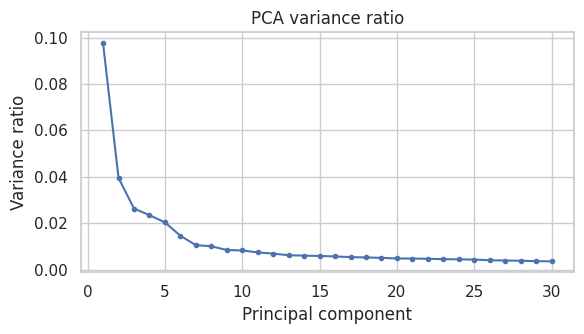

Cumulative variance in 30 PCs: 35.9%


In [5]:
# Library-size normalisation to the median, then log1p
target_sum = float(np.median(adata.obs["n_counts"]))
sc.pp.normalize_total(adata, target_sum=target_sum)
sc.pp.log1p(adata)
adata.layers["lognorm"] = adata.X.copy()

# PCA on scaled data (scaling is used only for PCA; X is restored afterwards)
sc.pp.scale(adata, max_value=10)
sc.pp.pca(adata, n_comps=CONFIG["preprocessing"]["n_pcs"], random_state=SEED)
adata.X = adata.layers["lognorm"].copy()

vr = adata.uns["pca"]["variance_ratio"]
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(np.arange(1, len(vr) + 1), vr, "o-", ms=3)
ax.set_xlabel("Principal component"); ax.set_ylabel("Variance ratio"); ax.set_title("PCA variance ratio")
plt.tight_layout(); fig.savefig(FIG_DIR / "pca_variance.png", dpi=200); plt.show()
print(f"Cumulative variance in {len(vr)} PCs: {vr.sum():.1%}")

In [6]:
sc.pp.neighbors(adata, n_neighbors=CONFIG["preprocessing"]["n_neighbors"],
                n_pcs=CONFIG["preprocessing"]["n_pcs"], random_state=SEED)

for r in CONFIG["clustering"]["resolutions"]:
    sc.tl.leiden(adata, resolution=r, key_added=f"leiden_r{r}", flavor="igraph",
                 n_iterations=2, directed=False, random_state=SEED)
    print(f"resolution {r}: {adata.obs[f'leiden_r{r}'].nunique()} clusters")

resolution 0.5: 15 clusters
resolution 1.0: 21 clusters
resolution 1.5: 30 clusters
resolution 2.0: 36 clusters


## Part D — Marker-based annotation with explicit uncertainty

Lineages are scored from the markers that are actually present on the Xenium panel. Each cluster receives a normalised marker score per lineage. A cluster is labelled **confident** only if (i) its best score is above a minimum and (ii) the runner-up is clearly lower. Otherwise it is labelled **Ambiguous** and is kept out of the training target.

In [7]:
MARKERS = {
    "Epithelial_luminal": ["EPCAM", "KRT7", "KRT8", "KRT18", "CEACAM6", "ESR1", "GATA3", "AGR3", "FOXA1", "ERBB2", "CDH1"],
    "Myoepithelial_basal": ["KRT5", "KRT14", "KRT15", "OXTR", "SFRP1"],
    "T_cell":     ["CD3D", "CD3E", "CD3G", "CD2", "CD4", "CD8A", "IL7R", "TRAC", "CCL5"],
    "B_cell":     ["MS4A1", "CD79A", "CD79B", "CD19", "BANK1"],
    "Plasma_cell": ["MZB1", "JCHAIN", "SDC1", "POU2AF1"],
    "Macrophage_myeloid": ["CD68", "CD163", "CD14", "LYZ", "AIF1", "CSF1R", "MRC1", "FCGR3A", "CD86"],
    "Dendritic_cell": ["CD1C", "CLEC9A", "LILRA4", "FCER1A", "ITGAX"],
    "Mast_cell":  ["KIT", "CPA3", "TPSAB1", "MS4A2"],
    "Endothelial": ["PECAM1", "VWF", "CLDN5", "EGFL7", "AQP1", "SELE", "CD34"],
    "Fibroblast_stromal": ["DCN", "LUM", "FAP", "COL1A1", "COL1A2", "PDGFRA", "MMP2", "CXCL12"],
    "Pericyte_smooth_muscle": ["ACTA2", "MYH11", "RGS5", "PDGFRB", "TAGLN", "CNN1", "MYLK"],
    "Adipocyte":  ["ADIPOQ", "ADH1B", "LPL", "FABP4", "PLIN1"],
}
PROLIF = ["MKI67", "TOP2A", "PCNA", "CENPF", "UBE2C"]   # cell-state score, not a lineage

rows, MARKERS_PRESENT = [], {}
for lin, genes in MARKERS.items():
    present = [g for g in genes if g in adata.var_names]
    missing = [g for g in genes if g not in adata.var_names]
    keep_lin = len(present) >= CONFIG["annotation"]["min_markers_per_lineage"]
    if keep_lin: MARKERS_PRESENT[lin] = present
    rows.append({"lineage": lin, "n_present": len(present), "present": ", ".join(present),
                 "missing": ", ".join(missing), "used": keep_lin})
marker_audit = pd.DataFrame(rows)

# Print as plain text to bypass the broken interactive table helper in Google Colab
print(marker_audit.to_string(index=False))

marker_audit.to_csv(TAB_DIR / "marker_panel_audit.csv", index=False)
print("\nLineages used:", list(MARKERS_PRESENT))

               lineage  n_present                                                           present                  missing  used
    Epithelial_luminal         10 EPCAM, KRT7, KRT8, CEACAM6, ESR1, GATA3, AGR3, FOXA1, ERBB2, CDH1                    KRT18  True
   Myoepithelial_basal          5                                   KRT5, KRT14, KRT15, OXTR, SFRP1                           True
                T_cell          8                     CD3D, CD3E, CD3G, CD4, CD8A, IL7R, TRAC, CCL5                      CD2  True
                B_cell          5                                  MS4A1, CD79A, CD79B, CD19, BANK1                           True
           Plasma_cell          1                                                              MZB1    JCHAIN, SDC1, POU2AF1 False
    Macrophage_myeloid          8                  CD68, CD163, CD14, LYZ, AIF1, MRC1, FCGR3A, CD86                    CSF1R  True
        Dendritic_cell          5                               CD1C, CLEC9A, LILRA

In [8]:
def cluster_mean_expression(adata, cluster_key, layer="lognorm"):
    cl = pd.Categorical(adata.obs[cluster_key].astype(str))
    codes, k, n = cl.codes, len(cl.categories), adata.n_obs
    ind = sp.csr_matrix((np.ones(n, dtype=np.float32), (codes, np.arange(n))), shape=(k, n))
    sums = ind @ adata.layers[layer]
    sums = sums.toarray() if sp.issparse(sums) else np.asarray(sums)
    sizes = np.bincount(codes, minlength=k)
    return pd.DataFrame(sums / sizes[:, None], index=cl.categories, columns=adata.var_names), \
           pd.Series(sizes, index=cl.categories, name="n_cells")


def annotate_clusters(adata, cluster_key, markers, min_top, amb_ratio):
    means, sizes = cluster_mean_expression(adata, cluster_key)
    span = means.max(0) - means.min(0)
    norm = (means - means.min(0)) / span.where(span > 0.05, np.inf)      # uninformative genes -> 0
    scores = pd.DataFrame({lin: norm[g].mean(1) for lin, g in markers.items()})
    arr = scores.to_numpy()
    order = np.argsort(-arr, axis=1)
    top_i, sec_i = order[:, 0], order[:, 1]
    r = np.arange(len(scores))
    table = pd.DataFrame({
        "n_cells": sizes,
        "top_lineage": scores.columns[top_i],
        "top_score": arr[r, top_i],
        "second_lineage": scores.columns[sec_i],
        "second_score": arr[r, sec_i],
    }, index=scores.index)
    table["score_ratio"] = table["second_score"] / table["top_score"].clip(lower=1e-9)
    table["confident"] = (table["top_score"] >= min_top) & (table["score_ratio"] < amb_ratio)
    table["label"] = np.where(table["confident"], table["top_lineage"], "Ambiguous")
    return table, scores


def label_cells(adata, cluster_key, markers, cfg):
    table, scores = annotate_clusters(adata, cluster_key, markers, cfg["min_top_score"], cfg["ambiguity_ratio"])
    labels = adata.obs[cluster_key].astype(str).map(table["label"])
    return labels, table, scores

ACFG = CONFIG["annotation"]
PRIMARY_KEY = f"leiden_r{CONFIG['clustering']['primary_resolution']}"
labels, cluster_table, cluster_scores = label_cells(adata, PRIMARY_KEY, MARKERS_PRESENT, ACFG)
adata.obs["lineage"] = pd.Categorical(labels)

# Print as plain text to bypass the broken interactive table helper in Google Colab
print(cluster_table.sort_values("n_cells", ascending=False).round(3).to_string())

cluster_table.round(4).to_csv(TAB_DIR / "cluster_annotation_table.csv")
cluster_scores.round(4).to_csv(TAB_DIR / "cluster_lineage_scores.csv")

    n_cells             top_lineage  top_score          second_lineage  second_score  score_ratio  confident                   label
4     21251      Epithelial_luminal      0.664     Myoepithelial_basal         0.034        0.051       True      Epithelial_luminal
11    19526                  T_cell      0.737      Fibroblast_stromal         0.370        0.502       True                  T_cell
15    19150      Fibroblast_stromal      0.966  Pericyte_smooth_muscle         0.341        0.352       True      Fibroblast_stromal
7     15171      Macrophage_myeloid      1.000          Dendritic_cell         0.803        0.803      False               Ambiguous
5     13202      Epithelial_luminal      0.879     Myoepithelial_basal         0.117        0.133       True      Epithelial_luminal
1     12667      Epithelial_luminal      0.862     Myoepithelial_basal         0.122        0.141       True      Epithelial_luminal
2     10943      Epithelial_luminal      0.662     Myoepithelial_basa

### Per-cell evidence: does each cell agree with its cluster's label?

In [9]:
genes_all = sorted({g for v in MARKERS_PRESENT.values() for g in v})
Xm = adata[:, genes_all].layers["lognorm"]
Xm = Xm.toarray() if sp.issparse(Xm) else np.asarray(Xm)
q99 = np.maximum(np.quantile(Xm, 0.99, axis=0), 0.5)
Xs = np.clip(Xm / q99, 0, 1)
gidx = {g: i for i, g in enumerate(genes_all)}
cell_scores = pd.DataFrame({lin: Xs[:, [gidx[g] for g in g_list]].mean(1) for lin, g_list in MARKERS_PRESENT.items()},
                           index=adata.obs_names)

cs = cell_scores.to_numpy()
cs_order = np.argsort(-cs, axis=1)
cell_top = cell_scores.columns[cs_order[:, 0]]
adata.obs["cell_top_lineage"] = pd.Categorical(cell_top)
adata.obs["cell_marker_margin"] = cs[np.arange(len(cs)), cs_order[:, 0]] - cs[np.arange(len(cs)), cs_order[:, 1]]
adata.obs["cell_marker_signal"] = cs.max(1)
adata.obs["cell_agrees_with_cluster"] = (adata.obs["cell_top_lineage"].astype(str) == adata.obs["lineage"].astype(str)).values

# Proliferation state (not a lineage)
pro = [g for g in PROLIF if g in adata.var_names]
if pro:
    adata.obs["proliferation_score"] = np.asarray(adata[:, pro].layers["lognorm"].mean(1)).ravel()

# Confidence tiers used downstream
conf = np.full(adata.n_obs, "low", dtype=object)
cluster_conf = adata.obs["lineage"].astype(str).ne("Ambiguous").values
agree = adata.obs["cell_agrees_with_cluster"].values
has_sig = (adata.obs["cell_marker_signal"].values > 0)
conf[cluster_conf & agree & has_sig] = "high"
conf[cluster_conf & ~agree & has_sig] = "medium"
conf[~has_sig] = "no_marker_signal"
conf[~cluster_conf] = "low"
adata.obs["label_confidence"] = pd.Categorical(conf, categories=["high", "medium", "low", "no_marker_signal"])

purity = (adata.obs.groupby("lineage", observed=True)["cell_agrees_with_cluster"].mean().rename("cell_level_agreement"))
summary = (adata.obs.groupby("lineage", observed=True).size().rename("n_cells").to_frame()
           .join(purity).assign(fraction=lambda d: d["n_cells"] / d["n_cells"].sum()).sort_values("n_cells", ascending=False))

# Bypass Colab's broken interactive formatter by printing plain-text tables
print("=== Lineage Composition Summary ===")
print(summary.round(3).to_string())
print("\n=== Label Confidence Value Counts ===")
print(adata.obs["label_confidence"].value_counts().to_frame("n_cells").assign(fraction=lambda d: d.n_cells / d.n_cells.sum()).round(3).to_string())

summary.round(4).to_csv(TAB_DIR / "lineage_composition.csv")

=== Lineage Composition Summary ===
                        n_cells  cell_level_agreement  fraction
lineage                                                        
Epithelial_luminal        65279                 0.974     0.398
T_cell                    28354                 0.609     0.173
Ambiguous                 27694                 0.000     0.169
Fibroblast_stromal        25044                 0.824     0.153
Endothelial                9070                 0.639     0.055
B_cell                     4012                 0.664     0.024
Pericyte_smooth_muscle     3824                 0.815     0.023
Mast_cell                   723                 0.961     0.004

=== Label Confidence Value Counts ===
                  n_cells  fraction
label_confidence                   
high               113729     0.693
low                 27694     0.169
medium              22564     0.138
no_marker_signal       13     0.000


### Evidence figures: marker dotplot, cluster-score heatmap, spatial map, UMAP

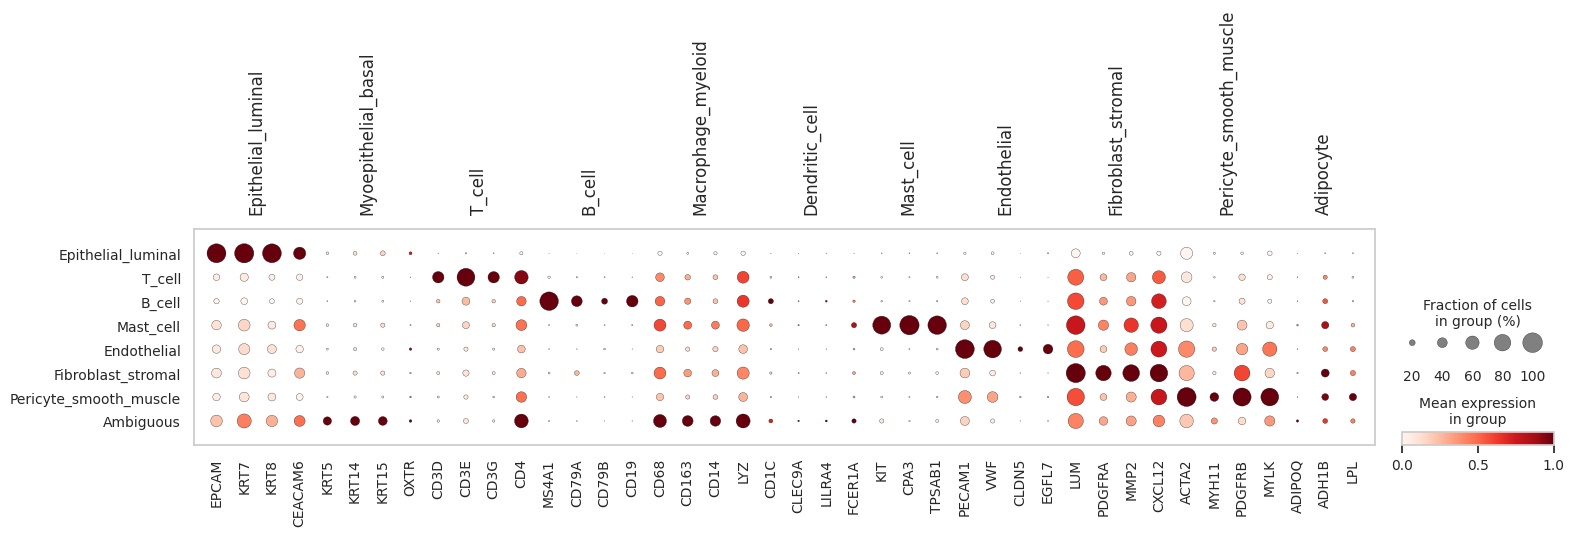

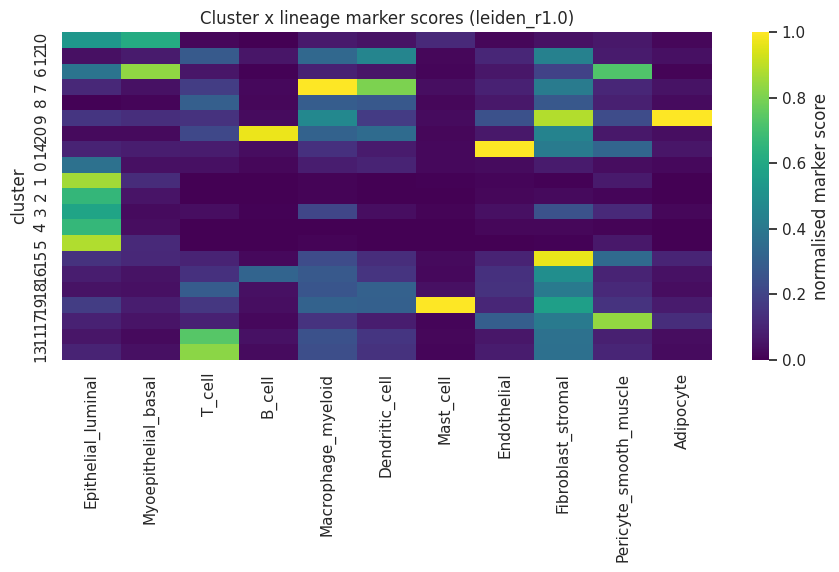

In [10]:
lineage_order = [l for l in MARKERS_PRESENT if l in adata.obs["lineage"].cat.categories] + \
                [l for l in adata.obs["lineage"].cat.categories if l not in MARKERS_PRESENT]
adata.obs["lineage"] = adata.obs["lineage"].cat.reorder_categories(lineage_order)

dp_genes = {lin: g[:4] for lin, g in MARKERS_PRESENT.items()}
sc.pl.dotplot(adata, dp_genes, groupby="lineage", standard_scale="var", show=False)
plt.savefig(FIG_DIR / "marker_dotplot.png", dpi=200, bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(9, max(5, 0.28 * len(cluster_scores))))
sns.heatmap(cluster_scores.loc[cluster_table.sort_values("label").index], cmap="viridis", ax=ax, cbar_kws={"label": "normalised marker score"})
ax.set_title(f"Cluster x lineage marker scores ({PRIMARY_KEY})"); ax.set_ylabel("cluster")
plt.tight_layout(); fig.savefig(FIG_DIR / "cluster_lineage_heatmap.png", dpi=200); plt.show()

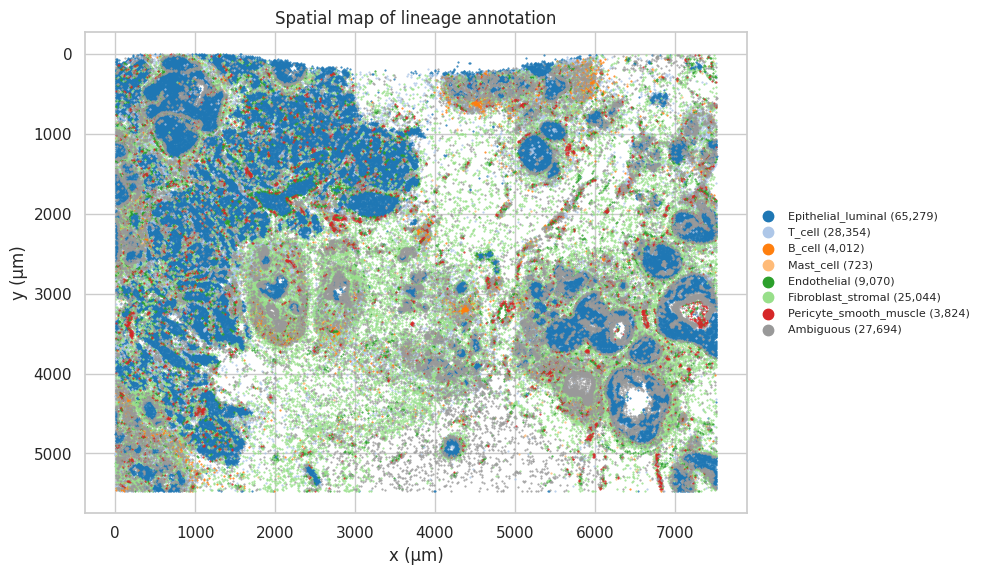

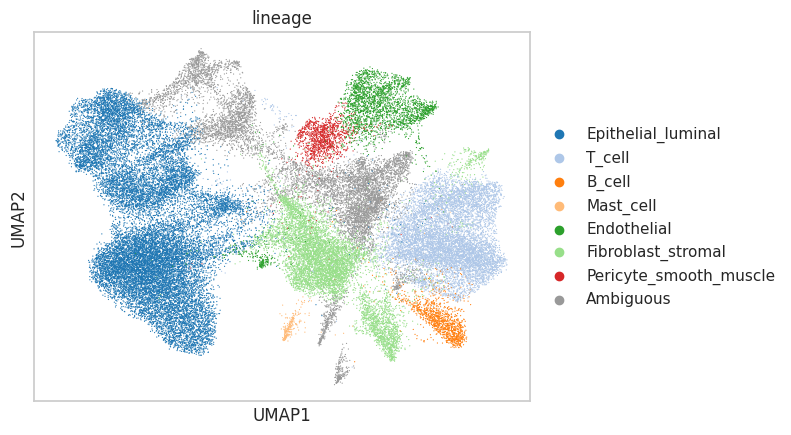

In [11]:
palette = dict(zip(adata.obs["lineage"].cat.categories,
                   sns.color_palette("tab20", n_colors=len(adata.obs["lineage"].cat.categories))))
palette["Ambiguous"] = (0.6, 0.6, 0.6)

xy = adata.obsm["spatial"]
fig, ax = plt.subplots(figsize=(10, 8))
for lin in adata.obs["lineage"].cat.categories:
    m = (adata.obs["lineage"] == lin).values
    ax.scatter(xy[m, 0], xy[m, 1], s=0.25, color=palette[lin], label=f"{lin} ({m.sum():,})", rasterized=True)
ax.set_aspect("equal"); ax.invert_yaxis()
ax.set_xlabel("x (µm)"); ax.set_ylabel("y (µm)"); ax.set_title("Spatial map of lineage annotation")
ax.legend(markerscale=15, fontsize=8, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.tight_layout(); fig.savefig(FIG_DIR / "spatial_lineage_map.png", dpi=200, bbox_inches="tight"); plt.show()

# UMAP on a random subsample (visualisation only; labels were not derived from it)
sub_idx = RNG.choice(adata.n_obs, size=min(50000, adata.n_obs), replace=False)
sub = adata[np.sort(sub_idx)].copy()
sc.pp.neighbors(sub, n_neighbors=15, use_rep="X_pca", random_state=SEED)
sc.tl.umap(sub, random_state=SEED)
sc.pl.umap(sub, color="lineage", palette=palette, s=3, show=False)
plt.savefig(FIG_DIR / "umap_lineage.png", dpi=200, bbox_inches="tight"); plt.show()
del sub

## Part E — Robustness checks
A label that changes with the clustering resolution or random seed is not a defensible label. We re-annotate with every resolution and several Leiden seeds and measure per-cell agreement with the primary labels.

In [12]:
label_sets = {PRIMARY_KEY: adata.obs["lineage"].astype(str)}
for r in CONFIG["clustering"]["resolutions"]:
    key = f"leiden_r{r}"
    if key not in adata.obs:
        sc.tl.leiden(adata, resolution=r, key_added=key, flavor="igraph", n_iterations=2, directed=False, random_state=SEED)
    labels_r, _, _ = label_cells(adata, key, MARKERS_PRESENT, ACFG)
    label_sets[f"leiden_r{r}"] = labels_r.astype(str)

for s in CONFIG["clustering"]["stability_seeds"]:
    key = f"seed{s}_r{CONFIG['clustering']['primary_resolution']}"
    if key not in adata.obs:
        sc.tl.leiden(adata, resolution=CONFIG["clustering"]["primary_resolution"], key_added=key, flavor="igraph", n_iterations=2, directed=False, random_state=s)
    labels_s, _, _ = label_cells(adata, key, MARKERS_PRESENT, ACFG)
    label_sets[key] = labels_s.astype(str)

ref = label_sets[PRIMARY_KEY]
rows_stab = []
for run_name, labs in label_sets.items():
    agree_pct = np.mean(labs == ref)
    ari = adjusted_rand_score(ref, labs)
    amb_pct = np.mean(labs == "Ambiguous")
    rows_stab.append({
        "annotation_run": run_name,
        "per_cell_agreement_with_primary": agree_pct,
        "adjusted_rand_index": ari,
        "fraction_ambiguous": amb_pct
    })
stab = pd.DataFrame(rows_stab)

# Bypass Colab's broken interactive formatter by printing as plain text
print("=== Annotation Robustness and Stability Summary ===")
print(stab.round(4).to_string(index=False))

stab.round(4).to_csv(TAB_DIR / "annotation_stability_analysis.csv", index=False)

=== Annotation Robustness and Stability Summary ===
annotation_run  per_cell_agreement_with_primary  adjusted_rand_index  fraction_ambiguous
   leiden_r1.0                           1.0000               1.0000              0.1689
   leiden_r0.5                           0.8426               0.8391              0.2928
   leiden_r1.5                           0.8491               0.8036              0.2064
   leiden_r2.0                           0.8530               0.8120              0.1818
    seed1_r1.0                           0.9794               0.9525              0.1786
    seed2_r1.0                           0.9454               0.9261              0.1509
    seed3_r1.0                           0.9356               0.9026              0.1673


## Part F — Independent validation: predict labels from non-marker genes
If the annotation reflects real biology, a classifier that **never sees the marker genes** should still recover the labels. This is a consistency check for the labels, not a spatial-generalisation test (that comes in Module 6). We use only high-confidence cells.

Non-marker genes available: 253
Balanced accuracy from non-marker genes only (5-fold CV): 0.914

=== Non-Marker-Gene Validation Classification Report ===
                        precision  recall  f1-score    support
B_cell                      0.663   0.849     0.745    980.000
Endothelial                 0.944   0.957     0.950   1978.000
Epithelial_luminal          0.997   0.993     0.995  22249.000
Fibroblast_stromal          0.965   0.956     0.960   7378.000
Mast_cell                   0.684   0.819     0.745    227.000
Pericyte_smooth_muscle      0.863   0.908     0.885   1114.000
T_cell                      0.955   0.917     0.936   6074.000
accuracy                    0.966   0.966     0.966      0.966
macro avg                   0.867   0.914     0.888  40000.000
weighted avg                0.968   0.966     0.967  40000.000


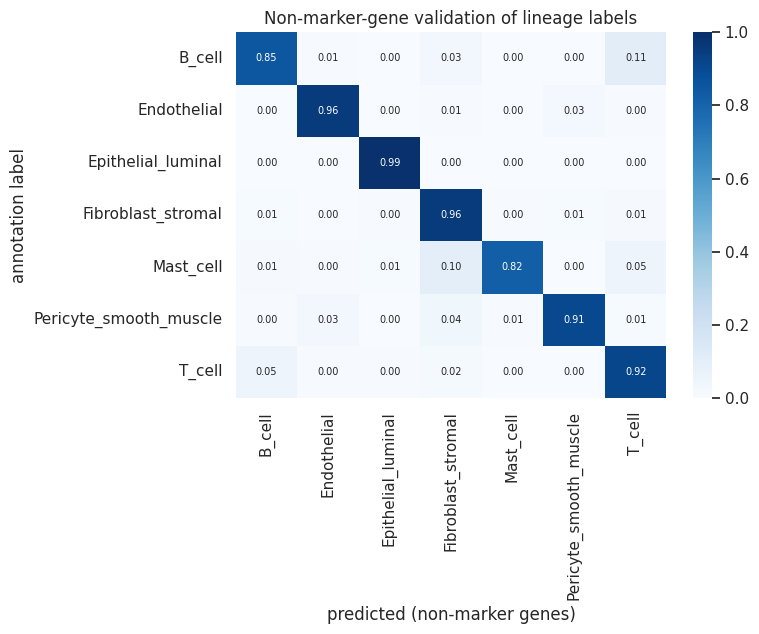

In [15]:
marker_set = set(genes_all)
nonmarker = [g for g in adata.var_names if g not in marker_set]
print(f"Non-marker genes available: {len(nonmarker)}")

high = adata.obs["label_confidence"].eq("high").values
cls_counts = adata.obs.loc[high, "lineage"].value_counts()
valid_cls = cls_counts[cls_counts >= 100].index.tolist()
sel = np.where(high & adata.obs["lineage"].isin(valid_cls).values)[0]

VCFG = CONFIG["validation"]
if len(sel) > VCFG["classifier_max_cells"]:
    sel = RNG.choice(sel, VCFG["classifier_max_cells"], replace=False)

Xc = adata[sel, nonmarker].layers["lognorm"]
Xc = Xc.toarray() if sp.issparse(Xc) else np.asarray(Xc)
yc = adata.obs["lineage"].astype(str).values[sel]
# Ensure yc is a native numpy array of strings to avoid PyArrow/Pandas 3 indexer TypeErrors in cross_val_predict
yc = np.asarray(yc, dtype=str)

clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=400, class_weight="balanced", n_jobs=-1))
skf = StratifiedKFold(n_splits=VCFG["cv_folds"], shuffle=True, random_state=SEED)
pred = cross_val_predict(clf, Xc, yc, cv=skf)

bal = balanced_accuracy_score(yc, pred)
print(f"Balanced accuracy from non-marker genes only ({VCFG['cv_folds']}-fold CV): {bal:.3f}\n")

rep = pd.DataFrame(classification_report(yc, pred, output_dict=True, zero_division=0)).T

# Bypass Colab's broken interactive formatter by printing as plain text
print("=== Non-Marker-Gene Validation Classification Report ===")
print(rep.round(3).to_string())

rep.round(4).to_csv(TAB_DIR / "nonmarker_validation_report.csv")

labs = sorted(set(yc))
cm = confusion_matrix(yc, pred, labels=labs, normalize="true")
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(cm, xticklabels=labs, yticklabels=labs, cmap="Blues", vmin=0, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax)
ax.set_xlabel("predicted (non-marker genes)"); ax.set_ylabel("annotation label")
ax.set_title("Non-marker-gene validation of lineage labels")
plt.tight_layout(); fig.savefig(FIG_DIR / "nonmarker_validation_confusion.png", dpi=200); plt.show()

## Part G — The biological target, defined so it cannot leak

**Question:** can spatial features and local composition predict the tissue microenvironment around a cell, beyond expression alone?

**Design decisions locked in now, before any model is trained**

| Element | Definition | Why |
|---|---|---|
| Unit | one cell (confident labels only as neighbors or targets) | clear and countable |
| Feature neighborhood | cells within **15 and 30 µm**, **excluding the cell itself** | local context |
| Target neighborhood | cells in an **annulus of 50–100 µm** around the cell | spatially disjoint from the feature neighborhood, so no shared cells |
| Target label | k-means class of lineage-composition fractions in the annulus (k chosen by stability, Module 3/4) | a microenvironment type, e.g. tumor-rich / immune-rich / stromal / boundary |
| Spatial CV | 500 µm blocks with a **100 µm buffer** between train and test | removes neighborhood overlap between folds |

**Known limitations to state in the final report**
- Lineage labels come from expression, so an expression-only model has partial circularity: it is a comparison, not a clean control.
- Tumor vs normal epithelium cannot be separated from a 313-gene panel without copy-number evidence.
- The labels are marker-based and unassigned/ambiguous cells are excluded from targets.

In [16]:
target_definition = {
    "research_question": "Can spatial features and local cellular composition predict the tissue microenvironment around a cell beyond expression alone?",
    "prediction_unit": "single cell",
    "target": {
        "name": "microenvironment_class",
        "source_labels": "lineage (confident clusters only)",
        "neighborhood_annulus_um": CONFIG["target_design"]["target_annulus_um"],
        "method": CONFIG["target_design"]["target_method"],
        "min_cells_in_annulus": CONFIG["target_design"]["min_cells_in_annulus"],
    },
    "features": {
        "spatial_radii_um": CONFIG["target_design"]["feature_neighborhood_radii_um"],
        "exclude_self": CONFIG["target_design"]["feature_neighborhood_includes_self"],
        "expression_features": "log-normalised expression of the cell itself",
        "excluded_from_features": ["raw x/y coordinates (unless explicitly tested as a spatial-only baseline)",
                                    "any quantity computed inside the target annulus"],
    },
    "evaluation": {
        "split": f"spatial blocks of {CONFIG['target_design']['spatial_cv_block_size_um']} um with {CONFIG['target_design']['spatial_cv_buffer_um']} um buffer",
        "models": ["expression-only", "spatial-only", "combined"],
        "metrics": ["balanced accuracy", "macro F1", "per-class recall"],
    },
    "label_quality": {
        "n_lineages": int(len(MARKERS_PRESENT)),
        "fraction_high_confidence": float((adata.obs["label_confidence"] == "high").mean()),
        "nonmarker_balanced_accuracy": float(bal),
    },
    "limitations": [
        "Expression-derived labels make the expression-only baseline partly circular.",
        "Tumor vs normal epithelium is not resolvable without CNV evidence.",
        "Single tissue section: spatial blocks are not independent biological replicates.",
    ],
}
with open(REP_DIR / "target_definition.json", "w") as f:
    json.dump(target_definition, f, indent=2)
print("Saved reports/target_definition.json")

Saved reports/target_definition.json


## Part H — Save deliverables

In [17]:
keep_cols = ["cell_id", "x_centroid", "y_centroid", "transcript_counts", "total_counts", "cell_area", "nucleus_area",
             "n_counts", "n_genes", PRIMARY_KEY, "lineage", "label_confidence", "cell_top_lineage",
             "cell_marker_margin", "cell_marker_signal", "cell_agrees_with_cluster"]
if "proliferation_score" in adata.obs: keep_cols.append("proliferation_score")
keep_cols = [c for c in keep_cols if c in adata.obs.columns]

adata.obs["lineage"] = adata.obs["lineage"].astype(str).astype("category")
adata.obs["label_confidence"] = adata.obs["label_confidence"].astype(str).astype("category")
adata.obs["cell_top_lineage"] = adata.obs["cell_top_lineage"].astype(str).astype("category")
adata.uns["config"] = json.dumps(CONFIG)

out_h5ad = PROC_DIR / "xenium_breast_annotated.h5ad"
adata.write_h5ad(out_h5ad, compression="gzip")
adata.obs[keep_cols].to_csv(TAB_DIR / "cell_annotations.csv.gz", index=False)

report = {
    "cells_after_qc": int(adata.n_obs),
    "genes": int(adata.n_vars),
    "n_lineages_used": len(MARKERS_PRESENT),
    "n_clusters_primary": int(adata.obs[PRIMARY_KEY].nunique()),
    "n_ambiguous_clusters": int((~cluster_table["confident"]).sum()),
    "fraction_cells_ambiguous": float((adata.obs["lineage"] == "Ambiguous").mean()),
    "fraction_high_confidence": float((adata.obs["label_confidence"] == "high").mean()),
    "min_agreement_across_runs": float(stab["per_cell_agreement_with_primary"].min()),
    "nonmarker_balanced_accuracy": float(bal),
    "outputs": {"h5ad": str(out_h5ad), "annotations": str(TAB_DIR / "cell_annotations.csv.gz")},
}
with open(REP_DIR / "notebook_02_annotation_report.json", "w") as f:
    json.dump(report, f, indent=2)
print(json.dumps(report, indent=2))

{
  "cells_after_qc": 164000,
  "genes": 313,
  "n_lineages_used": 11,
  "n_clusters_primary": 21,
  "n_ambiguous_clusters": 6,
  "fraction_cells_ambiguous": 0.1688658536585366,
  "fraction_high_confidence": 0.693469512195122,
  "min_agreement_across_runs": 0.842609756097561,
  "nonmarker_balanced_accuracy": 0.9138881053324095,
  "outputs": {
    "h5ad": "/content/drive/MyDrive/spatial_ml_breast_cancer/data/processed/xenium_breast_annotated.h5ad",
    "annotations": "/content/drive/MyDrive/spatial_ml_breast_cancer/results/tables/cell_annotations.csv.gz"
  }
}


## Checklist before moving to Notebook 03
- [ ] `marker_panel_audit.csv`: no lineage with all markers missing that you care about
- [ ] Dotplot: each lineage lights up its own markers
- [ ] Spatial map: tissue structure looks anatomically plausible (tumor mass, stroma, immune patches)
- [ ] Stability: agreement with primary labels is high across resolutions and seeds
- [ ] Non-marker validation: balanced accuracy is clearly above chance for major lineages
- [ ] Fraction of ambiguous / low-confidence cells is documented